# EDA Klasifikasi Gambar Dokumen

## Import dan konfigurasi

In [6]:
from pathlib import Path
import os
import sys
import subprocess
import pandas as pd

INPUT_ROOT = Path("/kaggle/input")
repo_candidates = list(INPUT_ROOT.rglob("scripts/config.py"))
if not repo_candidates:
    raise FileNotFoundError(
        "Repository belum ditambahkan sebagai Kaggle Input. "
        "Pilih Add Input dan tambahkan dataset repository."
    )
REPO_ROOT = repo_candidates[0].parent.parent

csv_candidates = list(INPUT_ROOT.rglob("train.csv"))
csv_candidates = [p for p in csv_candidates if (p.parent / "test.csv").exists()
                  and (p.parent / "sample_submission.csv").exists()]
if not csv_candidates:
    raise FileNotFoundError("Folder kompetisi berisi train.csv/test.csv/sample_submission.csv tidak ditemukan.")
DATA_ROOT = csv_candidates[0].parent

weight_candidates = list(INPUT_ROOT.rglob("efficientnet_b0_rwightman-7f5810bc.pth"))
os.environ["DOC_DATA_DIR"] = str(DATA_ROOT)
os.environ["DOC_CHECKPOINT_DIR"] = "/kaggle/working/checkpoint"
os.environ["DOC_SUBMISSION_DIR"] = "/kaggle/working/submissions"
os.environ["DOC_REPORT_DIR"] = "/kaggle/working/reports"
if weight_candidates:
    os.environ["DOC_WEIGHTS_PATH"] = str(weight_candidates[0])

sys.path.insert(0, str(REPO_ROOT))
os.chdir(REPO_ROOT)

print("Repository:", REPO_ROOT)
print("Dataset:", DATA_ROOT)
print("Pretrained weights:", weight_candidates[0])
print("Output: /kaggle/working")

import pandas as pd
import matplotlib.pyplot as plt
from scripts.config import CLASS_NAMES
from scripts.dataset import load_metadata, build_tiff_index, resolve_image_path, read_tiff_with_fallback

train_df, test_df, sample_df = load_metadata(DATA_ROOT)
print("Train:", train_df.shape, "| Test:", test_df.shape, "| Sample:", sample_df.shape)
display(train_df.head())


Repository: /kaggle/input/datasets/ameliawidia/document-image-classification/document-image-classification/kaggle-document-classification-repo
Dataset: /kaggle/input/competitions/document-image-classification-sd234504
Pretrained weights: /kaggle/input/datasets/ameliawidia/efficientnet-b0-pretrained/efficientnet_b0_rwightman-7f5810bc.pth
Output: /kaggle/working
Train: (32003, 4) | Test: (7994, 2) | Sample: (7994, 2)


,id,filename,class_name,label
0,train_00001,train/resume/50497291-7292.tif,resume,12
1,train_00002,train/scientific_publication/50728670-8670.tif,scientific_publication,13
2,train_00003,train/scientific_report/87112192.tif,scientific_report,14
3,train_00004,train/scientific_publication/10343650_10343655...,scientific_publication,13
4,train_00005,train/specification/2057960699_2057960701.tif,specification,15


In [7]:
FIGURE_DIR = Path("/kaggle/working/reports/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Folder hasil EDA:", FIGURE_DIR)

Folder hasil EDA: /kaggle/working/reports/figures


## Distribusi kelas

,jumlah
class_name,
advertisement,2012
budget,2004
email,2013
file_folder,2022
form,2005
handwritten,2026
invoice,1982
letter,1972
memo,1994


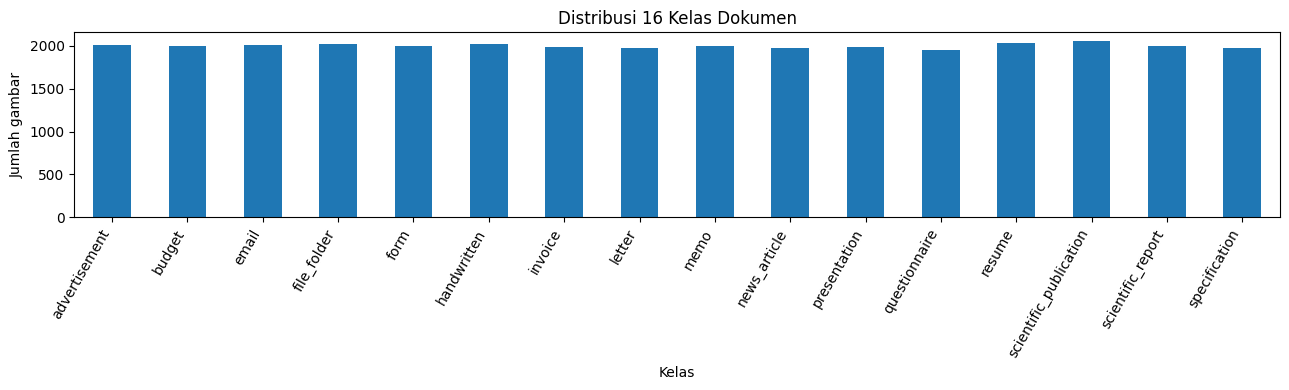

In [8]:
counts = train_df["class_name"].value_counts().reindex(CLASS_NAMES)

display(counts.rename("jumlah").to_frame())

ax = counts.plot(
    kind="bar",
    figsize=(13, 4),
    title="Distribusi 16 Kelas Dokumen"
)

ax.set_xlabel("Kelas")
ax.set_ylabel("Jumlah gambar")

plt.xticks(rotation=60, ha="right")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Contoh gambar tiap kelas

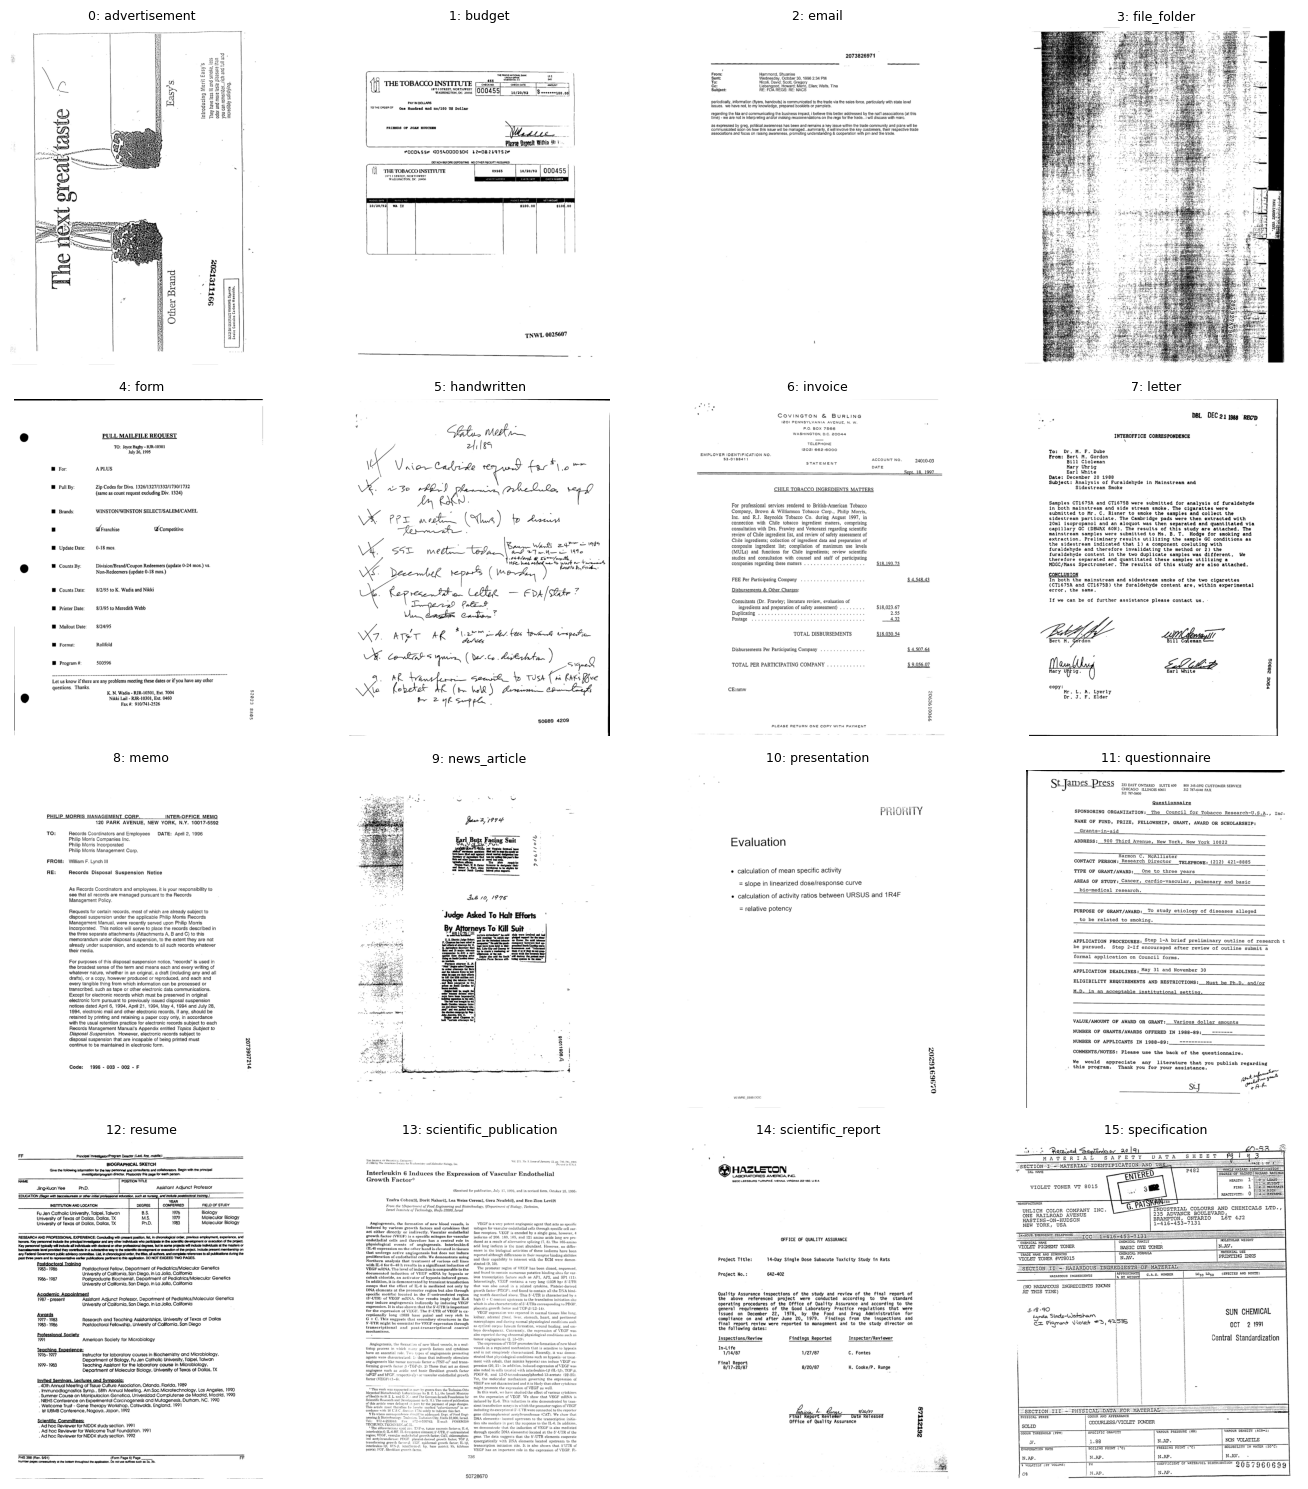

In [9]:
tiff_index = build_tiff_index(DATA_ROOT)

fig, axes = plt.subplots(4, 4, figsize=(14, 15))

for label, ax in enumerate(axes.flat):
    row = train_df[train_df["label"] == label].iloc[0]

    image_path = resolve_image_path(
        row["filename"],
        "train",
        DATA_ROOT,
        tiff_index,
        row["class_name"]
    )

    image = read_tiff_with_fallback(image_path)

    ax.imshow(image.convert("L"), cmap="gray")
    ax.set_title(
        f"{label}: {row['class_name']}",
        fontsize=9
    )
    ax.axis("off")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "sample_images.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Audit TIFF dan statistik ukuran/intensitas

In [10]:

import numpy as np
from tqdm.auto import tqdm
from scripts.dataset import validate_tiff_content

train_paths = [
    resolve_image_path(r.filename, "train", DATA_ROOT, tiff_index, r.class_name)
    for r in train_df.itertuples(index=False)
]
audit = [validate_tiff_content(p) for p in tqdm(train_paths)]
print("Valid:", sum(x[0] for x in audit), "| Invalid:", sum(not x[0] for x in audit))
print("Decoder:", pd.Series([x[1] for x in audit if x[0]]).value_counts().to_dict())

sample_ids = np.linspace(0, len(train_paths)-1, min(1000, len(train_paths)), dtype=int)
stats = []
for idx in tqdm(sample_ids):
    image = read_tiff_with_fallback(train_paths[idx])
    gray = np.asarray(image.convert("L"), dtype=np.float32)
    width, height = image.size
    stats.append({"width": width, "height": height, "aspect_ratio": width/max(height,1),
                  "gray_mean": float(gray.mean()), "gray_std": float(gray.std())})
stats_df = pd.DataFrame(stats)
display(stats_df.describe().T)


  0%|          | 0/32003 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Corrupt EXIF data.  Expecting to read 2 bytes but only got 0. 
  warnings.warn(str(msg))
<tifffile.TiffPages @85476> invalid offset to first page 85476


Valid: 32002 | Invalid: 1
Decoder: {'Pillow': 32002}


  0%|          | 0/1000 [00:00<?, ?it/s]

,count,mean,std,min,25%,50%,75%,max
width,1000.0,766.481000,32.578628,611.000000,754.000000,762.000000,777.000000,1473.000000
height,1000.0,1000.000000,0.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
aspect_ratio,1000.0,0.766481,0.032579,0.611000,0.754000,0.762000,0.777000,1.473000
gray_mean,1000.0,234.707498,27.756599,41.092648,233.892101,242.325943,247.564560,254.826187
gray_std,1000.0,50.629081,22.887046,5.583101,36.715586,47.320410,60.281578,126.009460


In [11]:
stats_df.to_csv(
    "/kaggle/working/reports/eda_image_statistics.csv",
    index=False
)

stats_df.describe().T.to_csv(
    "/kaggle/working/reports/eda_summary_statistics.csv"
)

print("Statistik EDA berhasil disimpan!")

Statistik EDA berhasil disimpan!
